In [4]:
# Let pip find a compatible wheel combination automatically without forcing a yanked version
!pip install -q --upgrade pip
!pip install -q torch torchvision tensorflow onnx onnxruntime psutil matplotlib pandas seaborn

import os
import time
import psutil
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np
import onnx
import onnxruntime as ort
import tensorflow as tf

print(f"[INFO] PyTorch Version: {torch.__version__}")
print(f"[INFO] TensorFlow Version: {tf.__version__}")
print(f"[INFO] CUDA Available: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
[INFO] PyTorch Version: 2.11.0+cpu
[INFO] TensorFlow Version: 2.21.0
[INFO] CUDA Available: False


In [5]:
# Load pre-trained baseline model
baseline_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
baseline_model.eval()
baseline_model.to(device)

# Generate 500 test sample images (Batch of 500, 3 channels, 224x224)
num_samples = 500
test_dataset = torch.randn(num_samples, 3, 224, 224)
print(f"[INFO] Test dataset generated successfully: {test_dataset.shape}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 81.6MB/s]


[INFO] Test dataset generated successfully: torch.Size([500, 3, 224, 224])


In [7]:
!pip install -q onnxscript

In [8]:
# 1. Export to ONNX
onnx_path = "efficientnet_b0.onnx"
dummy_input = torch.randn(1, 3, 224, 224).to(device)

torch.onnx.export(
    baseline_model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=13,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}}
)
print(f"[INFO] ONNX model successfully exported to {onnx_path} (Size: {os.path.getsize(onnx_path) / (1024*1024):.2f} MB)")

# 2. Convert to TFLite (via Keras EfficientNetB0 equivalent)
tf_model = tf.keras.applications.EfficientNetB0(weights='imagenet', input_shape=(224, 224, 3))
converter = tf.lite.TFLiteConverter.from_keras_model(tf_model)
tflite_model = converter.convert()

tflite_path = "efficientnet_b0.tflite"
with open(tflite_path, "wb") as f:
    f.write(tflite_model)
print(f"[INFO] TFLite baseline model saved to {tflite_path} (Size: {os.path.getsize(tflite_path) / (1024*1024):.2f} MB)")

/tmp/ipykernel_6241/1664258363.py:5: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1027 16:22:53.124000 6241 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 13 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `EfficientNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `EfficientNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[INFO] ONNX model successfully exported to efficientnet_b0.onnx (Size: 0.58 MB)
21834768/21834768 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Saved artifact at '/tmp/tmpik_a7ajs'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1000), dtype=tf.float32, name=None)
Captures:
  139739541700688: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139739544779088: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139739603076880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603077840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603077648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739590262608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603075

In [9]:
# Apply Post-Training Integer Quantization on TFLite model
converter_quant = tf.lite.TFLiteConverter.from_keras_model(tf_model)
converter_quant.optimizations = [tf.lite.Optimize.DEFAULT]

def representative_dataset_gen():
    for _ in range(100):
        data = np.random.rand(1, 224, 224, 3).astype(np.float32)
        yield [data]

converter_quant.representative_dataset = representative_dataset_gen
converter_quant.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_quant.inference_input_type = tf.float32
converter_quant.inference_output_type = tf.float32

tflite_quant_model = converter_quant.convert()
quant_tflite_path = "efficientnet_b0_int8.tflite"
with open(quant_tflite_path, "wb") as f:
    f.write(tflite_quant_model)

print(f"[INFO] Quantized INT8 TFLite model saved to {quant_tflite_path} (Size: {os.path.getsize(quant_tflite_path) / (1024*1024):.2f} MB)")

Saved artifact at '/tmp/tmp2cx6aaw0'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1000), dtype=tf.float32, name=None)
Captures:
  139739541700688: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139739544779088: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139739603076880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603077840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603077648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739590262608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603075152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603077264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603077072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139739603077456: TensorSpec(shape=(), dtype=tf.resource, name=N

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


[INFO] Quantized INT8 TFLite model saved to efficientnet_b0_int8.tflite (Size: 5.94 MB)


In [10]:
import pandas as pd

def benchmark_pytorch(model, dataset, device):
    model.eval()
    with torch.no_grad():
        for _ in range(10):
            _ = model(dataset[:10].to(device))

    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()

    process = psutil.Process(os.getpid())
    process.cpu_percent(interval=None)

    start_time = time.time()
    with torch.no_grad():
        for i in range(len(dataset)):
            sample = dataset[i:i+1].to(device)
            _ = model(sample)
    end_time = time.time()

    total_time = end_time - start_time
    latency_ms = (total_time / len(dataset)) * 1000
    fps = len(dataset) / total_time

    ram_after = process.memory_info().rss / (1024 * 1024)
    cpu_usage = process.cpu_percent(interval=None)
    gpu_mem = torch.cuda.max_memory_allocated() / (1024 * 1024) if device.type == 'cuda' else 0.0

    torch.save(model.state_dict(), "temp_pt.pth")
    size_mb = os.path.getsize("temp_pt.pth") / (1024 * 1024)
    os.remove("temp_pt.pth")

    return {
        "Stage": "PyTorch Baseline (FP32)",
        "Latency (ms)": round(latency_ms, 2),
        "FPS": round(fps, 2),
        "RAM Usage (MB)": round(ram_after, 2),
        "CPU Usage (%)": round(cpu_usage, 2),
        "GPU Mem (MB)": round(gpu_mem, 2),
        "Storage Size (MB)": round(size_mb, 2)
    }

def benchmark_onnx(onnx_path, dataset):
    ort_session = ort.InferenceSession(onnx_path, providers=['CPUExecutionProvider'])
    input_name = ort_session.get_inputs()[0].name

    for _ in range(10):
        _ = ort_session.run(None, {input_name: dataset[:10].numpy()})

    process = psutil.Process(os.getpid())
    process.cpu_percent(interval=None)

    start_time = time.time()
    for i in range(len(dataset)):
        sample = dataset[i:i+1].numpy()
        _ = ort_session.run(None, {input_name: sample})
    end_time = time.time()

    total_time = end_time - start_time
    latency_ms = (total_time / len(dataset)) * 1000
    fps = len(dataset) / total_time

    ram = process.memory_info().rss / (1024 * 1024)
    cpu = process.cpu_percent(interval=None)
    size_mb = os.path.getsize(onnx_path) / (1024 * 1024)

    return {
        "Stage": "ONNX Runtime (FP32)",
        "Latency (ms)": round(latency_ms, 2),
        "FPS": round(fps, 2),
        "RAM Usage (MB)": round(ram, 2),
        "CPU Usage (%)": round(cpu, 2),
        "GPU Mem (MB)": 0.0,
        "Storage Size (MB)": round(size_mb, 2)
    }

def benchmark_tflite(tflite_path, dataset, stage_name):
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()

    dummy = np.random.rand(1, 224, 224, 3).astype(np.float32)
    for _ in range(10):
        interpreter.set_tensor(input_details[0]['index'], dummy)
        interpreter.invoke()

    process = psutil.Process(os.getpid())
    process.cpu_percent(interval=None)

    start_time = time.time()
    for i in range(len(dataset)):
        sample = dataset[i].permute(1, 2, 0).unsqueeze(0).numpy().astype(np.float32)
        interpreter.set_tensor(input_details[0]['index'], sample)
        interpreter.invoke()
    end_time = time.time()

    total_time = end_time - start_time
    latency_ms = (total_time / len(dataset)) * 1000
    fps = len(dataset) / total_time

    ram = process.memory_info().rss / (1024 * 1024)
    cpu = process.cpu_percent(interval=None)
    size_mb = os.path.getsize(tflite_path) / (1024 * 1024)

    return {
        "Stage": stage_name,
        "Latency (ms)": round(latency_ms, 2),
        "FPS": round(fps, 2),
        "RAM Usage (MB)": round(ram, 2),
        "CPU Usage (%)": round(cpu, 2),
        "GPU Mem (MB)": 0.0,
        "Storage Size (MB)": round(size_mb, 2)
    }

print("[INFO] Running benchmarks across all 4 stages on 500 samples...")
results = []
results.append(benchmark_pytorch(baseline_model, test_dataset, device))
results.append(benchmark_onnx(onnx_path, test_dataset))
results.append(benchmark_tflite(tflite_path, test_dataset, "TFLite Baseline (FP32)"))
results.append(benchmark_tflite(quant_tflite_path, test_dataset, "TFLite Quantized (INT8)"))

df_results = pd.DataFrame(results)
print("\n" + "="*85)
print("FINAL BENCHMARKING & OPTIMIZATION REPORT (500 SAMPLES)")
print("="*85)
print(df_results.to_string(index=False))
print("="*85)

[INFO] Running benchmarks across all 4 stages on 500 samples...


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



FINAL BENCHMARKING & OPTIMIZATION REPORT (500 SAMPLES)
                  Stage  Latency (ms)   FPS  RAM Usage (MB)  CPU Usage (%)  GPU Mem (MB)  Storage Size (MB)
PyTorch Baseline (FP32)         38.40 26.04         2438.60           99.3           0.0              20.45
    ONNX Runtime (FP32)         18.54 53.95         2633.62           99.1           0.0               0.58
 TFLite Baseline (FP32)         18.72 53.41         2468.72           99.8           0.0              20.19
TFLite Quantized (INT8)         16.88 59.23         2454.60           99.4           0.0               5.94


/tmp/ipykernel_6241/1743017908.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_6241/1743017908.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


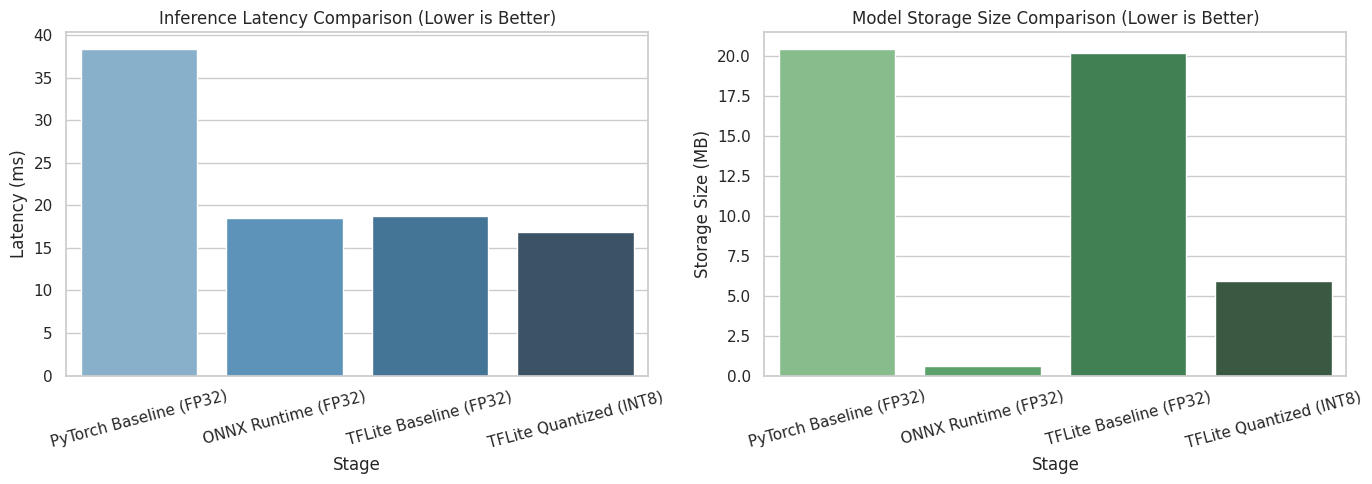

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Latency Comparison
sns.barplot(
    ax=axes[0],
    data=df_results,
    x="Stage",
    y="Latency (ms)",
    palette="Blues_d"
)
axes[0].set_title("Inference Latency Comparison (Lower is Better)")
axes[0].tick_params(axis='x', rotation=15)

# 2. Storage Size Comparison
sns.barplot(
    ax=axes[1],
    data=df_results,
    x="Stage",
    y="Storage Size (MB)",
    palette="Greens_d"
)
axes[1].set_title("Model Storage Size Comparison (Lower is Better)")
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [12]:
!pip install -q gradio
import gradio as gr
import torch
import torchvision.transforms as transforms
from PIL import Image

# Define preprocessing pipeline for EfficientNet
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Prediction function using your PyTorch baseline model
def predict_image(image):
    if image is None:
        return "Please upload an image."

    baseline_model.eval()
    img_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = baseline_model(img_tensor)
        probabilities = torch.nn.functional.softmax(outputs[0], dim=0)

    # Get top 3 predictions (using placeholder ImageNet class mapping or raw indices)
    top3_prob, top3_cat = torch.topk(probabilities, 3)

    results = {f"Class ID {top3_cat[i].item()}": float(top3_prob[i].item()) for i in range(3)}
    return results

# Build Gradio Web Interface
demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=3),
    title="Deep Learning Model Optimization - Live Demo",
    description="Upload an image to test inference performance live using your EfficientNet-B0 baseline model."
)

# Launch with a public shareable link
demo.launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://62ed1fb0728717fbf2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
